<a href="https://colab.research.google.com/github/earnrujanavej/Music-and-Mental-Health-/blob/main/Mental_Health_and_Music_Earn_R_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Examining the Potential Association between Depression and Music Interests
Earn R.

## Libraries and Data Loading

In [ ]:
# Libraries--

# General Purpose
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE

# ML Models and Metrics
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
data.to_csv("data.csv", index=False)

from google.colab import files
files.download("data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Mount Drive (unique to Colab)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load in raw data
path = '/content/drive/MyDrive/Mental Health and Music/mxmh_survey_results (1).csv'
data = pd.read_csv(path)
data.head()

,Timestamp,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,...,Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects,Permissions
0,8/27/2022 19:29:02,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,Yes,Yes,...,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN,I understand.
1,8/27/2022 19:57:31,63.0,Pandora,1.5,Yes,No,No,Rock,Yes,No,...,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN,I understand.
2,8/27/2022 21:28:18,18.0,Spotify,4.0,No,No,No,Video game music,No,Yes,...,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect,I understand.
3,8/27/2022 21:40:40,61.0,YouTube Music,2.5,Yes,No,Yes,Jazz,Yes,Yes,...,Sometimes,Never,Never,Never,9.0,7.0,3.0,3.0,Improve,I understand.
4,8/27/2022 21:54:47,18.0,Spotify,4.0,Yes,No,No,R&B,Yes,No,...,Very frequently,Very frequently,Never,Rarely,7.0,2.0,5.0,9.0,Improve,I understand.


## Exploratory Data Analysis

In [ ]:
data.info() # Added ()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 736 entries, 0 to 735
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Timestamp                     736 non-null    object 
 1   Age                           735 non-null    float64
 2   Primary streaming service     735 non-null    object 
 3   Hours per day                 736 non-null    float64
 4   While working                 733 non-null    object 
 5   Instrumentalist               732 non-null    object 
 6   Composer                      735 non-null    object 
 7   Fav genre                     736 non-null    object 
 8   Exploratory                   736 non-null    object 
 9   Foreign languages             732 non-null    object 
 10  BPM                           629 non-null    float64
 11  Frequency [Classical]         736 non-null    object 
 12  Frequency [Country]           736 non-null    object 
 13  Frequ

<Axes: xlabel='Fav genre', ylabel='Age'>

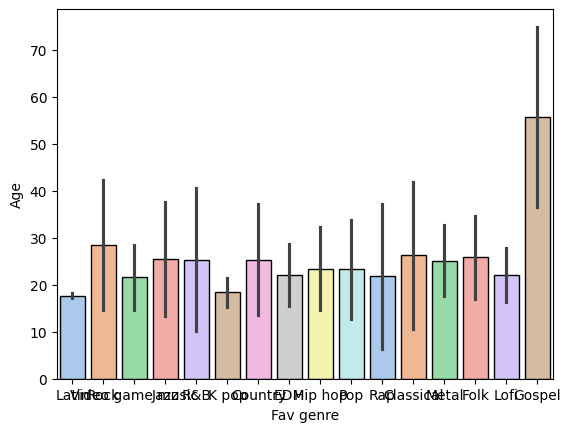

In [ ]:
sns.barplot(
    data=data,
    x="Fav genre",
    y="Age",
    hue="Fav genre",
    palette="pastel",
    edgecolor="black",
    linewidth=1,
    estimator="mean",
    errorbar="sd"
    )

<Axes: xlabel='Music effects', ylabel='Hours per day'>

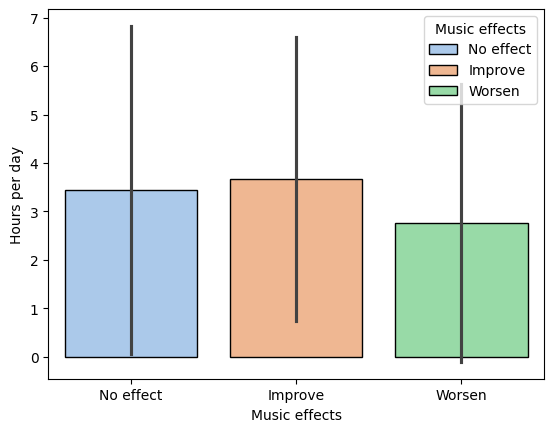

In [ ]:
sns.barplot(
    data=data,
    x="Music effects",
    y="Hours per day",
    hue="Music effects",
    palette="pastel",
    edgecolor="black",
    linewidth=1,
    estimator="mean",
    errorbar="sd"
)

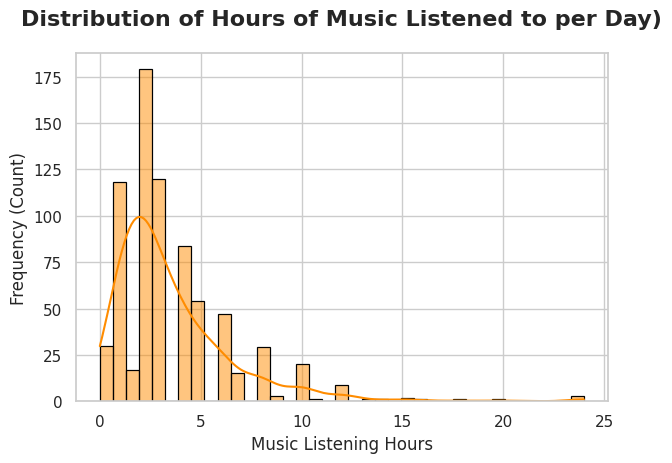

In [ ]:
sns.set_theme(style="whitegrid")

sns.histplot(
    data=data,
    x="Hours per day",
    bins="auto",
    kde=True,
    color="darkorange",
    edgecolor="black"
)

plt.title(
    'Distribution of Hours of Music Listened to per Day)',
    fontsize=16,
    fontweight='bold',
    pad=20
)

plt.xlabel('Music Listening Hours', fontsize=12)
plt.ylabel('Frequency (Count)', fontsize=12)

plt.tight_layout()
plt.show()


<Axes: xlabel='Hours per day', ylabel='Count'>

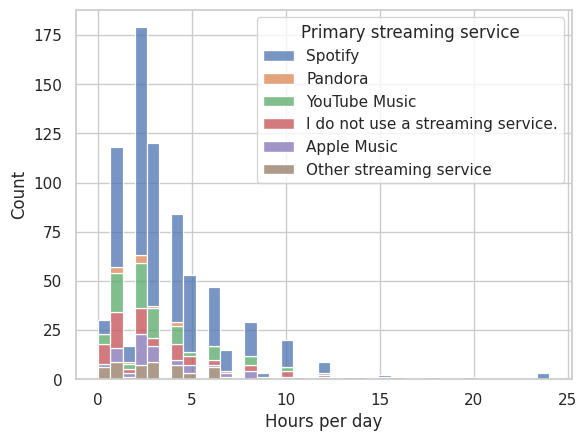

In [ ]:
sns.histplot(
    data=data,
    x="Hours per day",
    hue = "Primary streaming service",
    multiple = "stack")

<Axes: xlabel='Frequency [R&B]', ylabel='Age'>

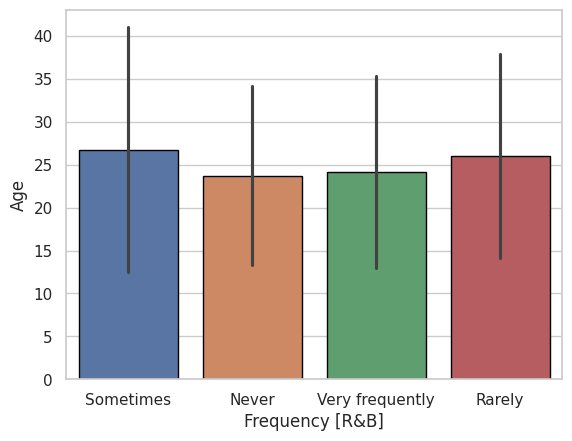

In [ ]:
sns.barplot(
    data=data,
    x="Frequency [R&B]",
    y="Age",
    hue="Frequency [R&B]",
    edgecolor="black",
    linewidth=1,
    estimator="mean",
    errorbar="sd"
    )

## Data Preprocessing

In [ ]:
# Removing irrelevant columns and other outcomes besides depression
drop_cols = ["Timestamp", "Permissions", "Anxiety", "Insomnia", "OCD", "Exploratory", "Composer"] # Removed "primary streaming service"
data_dropped_cols = data.drop(columns=drop_cols)
print(f"After dropping irrelevant columns: {data_dropped_cols.shape}")

After dropping irrelevant columns: (736, 26)


In [ ]:
# # Original Categories - 4 groups
# data_dropped_cols["Depression_class"] = pd.cut(
#     data_dropped_cols["Depression"],
#     bins=[-1, 2, 4, 6, 10],
#     labels=[0, 1, 2, 3]
# ).astype(int)

# data_depression_cat = data_dropped_cols.drop(columns=["Depression"])

# label_map = {0: "Minimal (0-2)", 1: "Mild (3-4)", 2: "Moderate (5-6)", 3: "Severe (7-10)"}
# print("\nDepression class distribution:")
# for k, v in label_map.items():
#     count = (data_depression_cat["Depression_class"] == k).sum()
#     print(f"  {k} — {v}: {count} ({count/len(data_depression_cat)*100:.1f}%)")

In [ ]:
# Updated Categories - 3 groups
data_dropped_cols["Depression_class"] = pd.cut(
    data_dropped_cols["Depression"],
    bins=[-1, 2, 6, 10],
    labels=[0, 1, 2]
).astype(int)

data_depression_cat = data_dropped_cols.drop(columns=["Depression"])

label_names = ["Low", "Moderate", "High"]
print("Depression class distribution:")
for k, v in {0: "Low", 1: "Moderate", 2: "High"}.items():
    count = (data_depression_cat["Depression_class"] == k).sum()
    print(f"  {k} — {v}: {count} ({count/len(data_depression_cat)*100:.1f}%)")

# Given our results so far I can even see a case for making it a binary variable (Depressed/Not Depressed)

Depression class distribution:
  0 — Low: 217 (29.5%)
  1 — Moderate: 263 (35.7%)
  2 — High: 256 (34.8%)


In [ ]:
# Outlier Capping
print(f"\nBPM missing before outlier capping: {data_depression_cat['BPM'].isna().sum()}")
data_depression_cat["BPM"] = data_depression_cat["BPM"].where(data_depression_cat["BPM"].between(40, 220), other=np.nan)
print(f"BPM missing after outlier capping : {data_depression_cat['BPM'].isna().sum()}")


BPM missing before outlier capping: 107
BPM missing after outlier capping : 115


In [ ]:
# Column Category Mapping
binary_cols = ["While working", "Instrumentalist", "Foreign languages"]
for col in binary_cols:
    data_depression_cat[col] = data_depression_cat[col].map({"Yes": 1, "No": 0})

FREQ_ORDER = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Very frequently": 3}
freq_cols = [c for c in data_depression_cat.columns if c.startswith("Frequency")]
for col in freq_cols:
    data_depression_cat[col] = data_depression_cat[col].map(FREQ_ORDER)

EFFECTS_ORDER = {"Worsen": 0, "No effect": 1, "Improve": 2}
data_depression_cat["Music effects"] = data_depression_cat["Music effects"].map(EFFECTS_ORDER)

print(f"\nMissing values before KNN imputation:")
missing = data_depression_cat.isnull().sum()
print(missing[missing > 0].to_string())


Missing values before KNN imputation:
Age                            1
Primary streaming service      1
While working                  3
Instrumentalist                4
Foreign languages              4
BPM                          115
Music effects                  8


In [ ]:
# Numeric and Nominal Column Setup
NOMINAL_COLS = ["Fav genre", "Primary streaming service"] # Re-added primary streaming service

temp_numeric_cols = [c for c in data_depression_cat.columns if c not in NOMINAL_COLS + ["Depression_class"]]

problematic_cols = []
if 'While working' in temp_numeric_cols and data_depression_cat['While working'].isnull().all():
    problematic_cols.append('While working')
if 'Instrumentalist' in temp_numeric_cols and data_depression_cat['Instrumentalist'].isnull().all():
    problematic_cols.append('Instrumentalist')

numeric_cols = [col for col in temp_numeric_cols if col not in problematic_cols]

In [ ]:
# X and y
X_numeric = data_depression_cat[numeric_cols]
X_nominal = data_depression_cat[NOMINAL_COLS]
y = data_depression_cat["Depression_class"]

# Train/Test Split with numeric and nominal X's
(X_num_train, X_num_test,
 X_nom_train, X_nom_test,
 y_train, y_test) = train_test_split(
    X_numeric, X_nominal, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train size : {X_num_train.shape[0]} rows")
print(f"Test size  : {X_num_test.shape[0]} rows")
print(f"Numeric features going into KNN: {X_num_train.shape[1]}")

Train size : 588 rows
Test size  : 148 rows
Numeric features going into KNN: 23


In [ ]:
# data.isna().mean() * 100

# Revised Examination of Missingness (on preprocessed dataset)
missing_counts = data_depression_cat.isnull().sum()
missing_pct = (missing_counts / len(data_depression_cat)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing %": missing_pct.round(2)
}).query("`Missing Count` > 0").sort_values("Missing %", ascending=False)

print(missing_summary)

                           Missing Count  Missing %
BPM                                  115      15.62
Music effects                          8       1.09
Foreign languages                      4       0.54
Instrumentalist                        4       0.54
While working                          3       0.41
Primary streaming service              1       0.14
Age                                    1       0.14


In [ ]:
# Scaling numeric data
scaler = MinMaxScaler()
X_num_train_scaled = scaler.fit_transform(X_num_train)
X_num_test_scaled  = scaler.transform(X_num_test)

# Imputing missing data (KNN is a distance based algorithm, so scaling must come first)
knn_imputer = KNNImputer(n_neighbors=5, weights="distance")
X_num_train_imputed = knn_imputer.fit_transform(X_num_train_scaled)
X_num_test_imputed  = knn_imputer.transform(X_num_test_scaled)

X_num_train_final = pd.DataFrame(
    X_num_train_imputed,
    columns=numeric_cols,
    index=X_num_train.index
)
X_num_test_final = pd.DataFrame(
    X_num_test_imputed,
    columns=numeric_cols,
    index=X_num_test.index
)

assert X_num_train_final.isnull().sum().sum() == 0, "Missing values remain in train!"
assert X_num_test_final.isnull().sum().sum()  == 0, "Missing values remain in test!"
print("✅ KNN imputation complete — no remaining missing values")

✅ KNN imputation complete — no remaining missing values


In [ ]:
X_nom_train_enc = pd.get_dummies(
    X_nom_train,
    prefix=["genre", "stream"],
    drop_first=True # Perhaps we switch to false for greater interpretability given the columns we have
)

X_nom_test_enc = pd.get_dummies(
    X_nom_test,
    prefix=["genre", "stream"],
    drop_first=True # Perhaps we switch to false for greater interpretability given the columns we have
)

X_nom_test_enc = X_nom_test_enc.reindex(columns=X_nom_train_enc.columns, fill_value=0)

for df_enc in [X_nom_train_enc, X_nom_test_enc]:
    bool_cols = df_enc.select_dtypes(include="bool").columns
    df_enc[bool_cols] = df_enc[bool_cols].astype(int)

In [ ]:
# Combined training and test data
X_train = pd.concat([X_num_train_final.reset_index(drop=True),
                     X_nom_train_enc.reset_index(drop=True)], axis=1)
X_test  = pd.concat([X_num_test_final.reset_index(drop=True),
                     X_nom_test_enc.reset_index(drop=True)],  axis=1)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

print(f"Final feature matrix — Train: {X_train.shape}, Test: {X_test.shape}")
print(f"\nScaled numeric cols   : {len(numeric_cols)}")
print(f"One-hot encoded cols  : {len(X_nom_train_enc.columns)}")
print(f"Total features        : {X_train.shape[1]}")

Final feature matrix — Train: (588, 43), Test: (148, 43)

Scaled numeric cols   : 23
One-hot encoded cols  : 20
Total features        : 43


In [ ]:
# Class Balancing (SMOTE); only for training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE — Train size: {X_train.shape[0]}")
print(f"After SMOTE  — Train size: {X_train_smote.shape[0]}")
print(f"\nClass distribution after SMOTE:")
for k, v in {0: "Low", 1: "Moderate", 2: "High"}.items():
    count = (y_train_smote == k).sum()
    print(f"  {k} — {v}: {count} ({count/len(y_train_smote)*100:.1f}%)")

Before SMOTE — Train size: 588
After SMOTE  — Train size: 630

Class distribution after SMOTE:
  0 — Low: 210 (33.3%)
  1 — Moderate: 210 (33.3%)
  2 — High: 210 (33.3%)


## KNN

Best K: 1 (macro F1: 0.433)


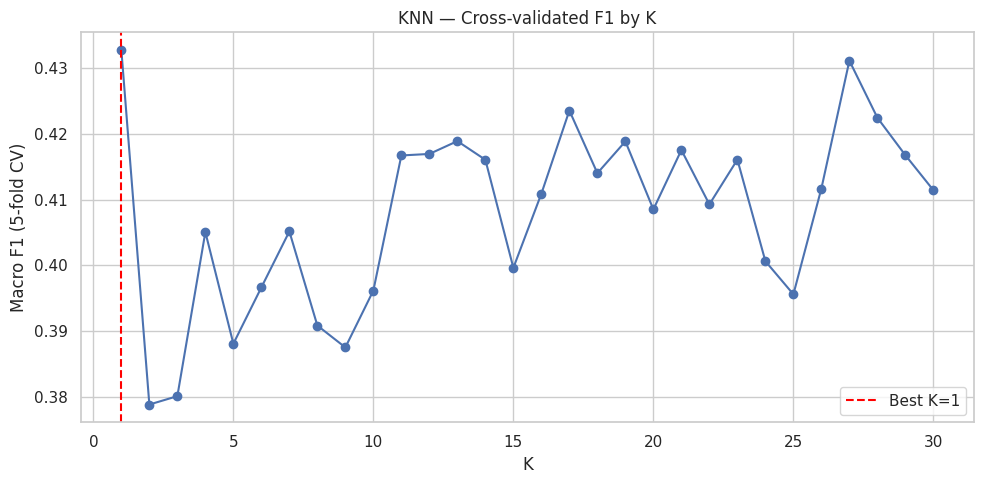

In [ ]:
# Setting up range of K's to test
k_range = range(1, 31)
cv_scores = []

# Testing the algorithm across all K's
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    scores = cross_val_score(knn, X_train_smote, y_train_smote, cv=5, scoring="f1_macro")
    cv_scores.append(scores.mean())

best_k = k_range[cv_scores.index(max(cv_scores))]
print(f"Best K: {best_k} (macro F1: {max(cv_scores):.3f})")

plt.figure(figsize=(10, 5))
plt.plot(k_range, cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"Best K={best_k}")
plt.xlabel("K")
plt.ylabel("Macro F1 (5-fold CV)")
plt.title("KNN — Cross-validated F1 by K")
plt.legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

         Low       0.31      0.36      0.34        44
    Moderate       0.39      0.38      0.38        53
        High       0.35      0.31      0.33        51

    accuracy                           0.35       148
   macro avg       0.35      0.35      0.35       148
weighted avg       0.35      0.35      0.35       148



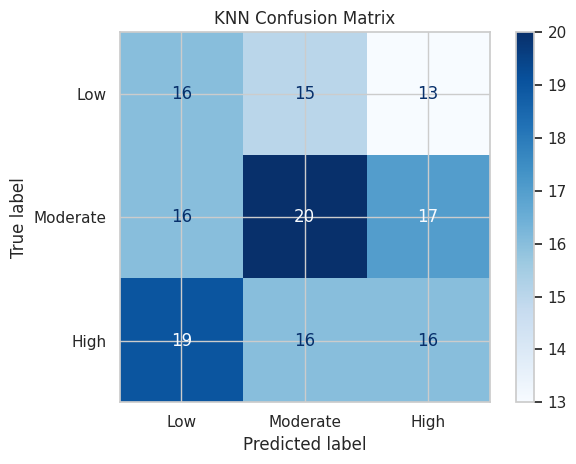

In [ ]:
# Updated label names!
label_names = ["Low", "Moderate", "High"]

# Evaluating the model with the highest performing "K"
knn_model = KNeighborsClassifier(n_neighbors=best_k, metric="euclidean")
knn_model.fit(X_train_smote, y_train_smote)

y_pred = knn_model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=label_names))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=label_names,
    cmap="Blues"
)
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

## Logistic Regression

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


              precision    recall  f1-score   support

         Low       0.37      0.59      0.45        44
    Moderate       0.53      0.40      0.45        53
        High       0.57      0.41      0.48        51

    accuracy                           0.46       148
   macro avg       0.49      0.47      0.46       148
weighted avg       0.49      0.46      0.46       148



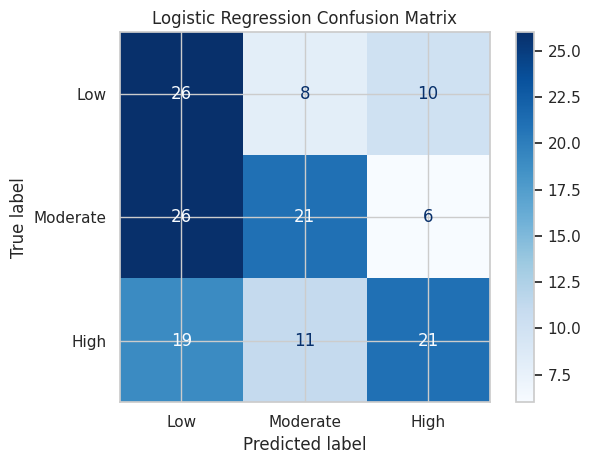


Top 5 features → Low:
Age                                         1.107624
Frequency [Country]                         0.588975
stream_YouTube Music                        0.522520
Frequency [K pop]                           0.363851
stream_I do not use a streaming service.    0.243578
Name: Low, dtype: float64

Top 5 features → Moderate:
genre_Latin           0.744989
genre_Rap             0.558670
Music effects         0.479998
Frequency [Rock]      0.477280
Frequency [Gospel]    0.453413
Name: Moderate, dtype: float64

Top 5 features → High:
Hours per day     0.722141
genre_Lofi        0.710778
genre_Hip hop     0.640550
genre_Folk        0.551046
stream_Pandora    0.493315
Name: High, dtype: float64


In [ ]:
# Updated label names!
label_names = ["Low", "Moderate", "High"]

lr_model = LogisticRegression(
    multi_class="multinomial",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_smote, y_train_smote)

y_pred_lr = lr_model.predict(X_test)
print(classification_report(y_test, y_pred_lr, target_names=label_names))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    display_labels=label_names,
    cmap="Blues"
)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

coef_df = pd.DataFrame(
    lr_model.coef_,
    index=label_names,
    columns=X_train.columns
)

for cls in label_names:
    print(f"\nTop 5 features → {cls}:")
    print(coef_df.loc[cls].sort_values(ascending=False).head())

## Random Forest

In [ ]:
rf = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train_smote, y_train_smote)

print("Best Parameters:")
print(grid_search.best_params_)

print(f"Best CV Score: {grid_search.best_score_:.3f}")

Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Score: 0.473


In [ ]:
best_rf = grid_search.best_estimator_

best_rf.fit(X_train_smote, y_train_smote)

RandomForestClassifier(max_depth=20, min_samples_leaf=2, min_samples_split=5,
                       random_state=42)

In [ ]:
y_pred_rf = best_rf.predict(X_test)

In [ ]:
# Updated label names!
label_names = ["Low", "Moderate", "High"]

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_names
))

              precision    recall  f1-score   support

         Low       0.48      0.57      0.52        44
    Moderate       0.58      0.53      0.55        53
        High       0.54      0.51      0.53        51

    accuracy                           0.53       148
   macro avg       0.54      0.54      0.53       148
weighted avg       0.54      0.53      0.53       148



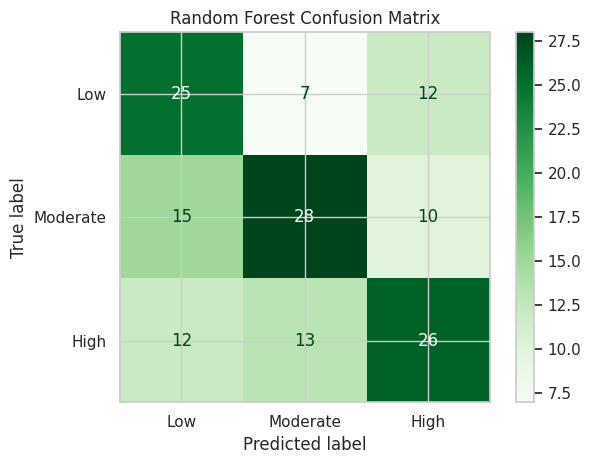

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=label_names,
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

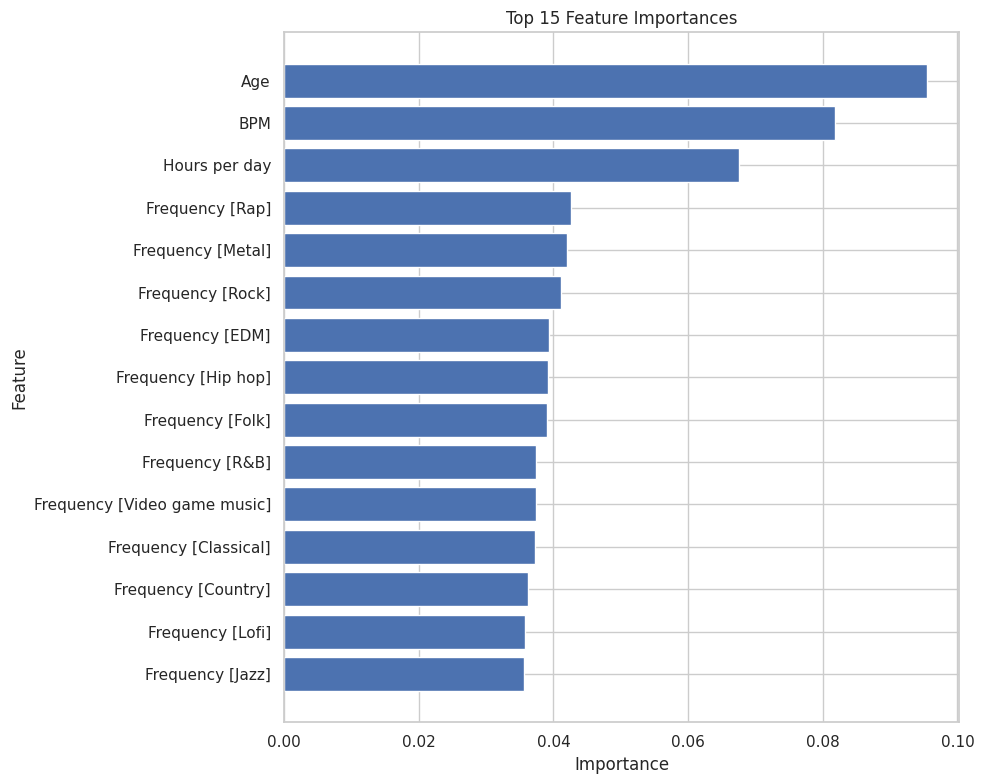

In [ ]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,8))

plt.barh(
    importance["Feature"][:15][::-1],
    importance["Importance"][:15][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances")

plt.tight_layout()
plt.show()

In [ ]:
print(importance.head(15))

                         Feature  Importance
0                            Age    0.095483
5                            BPM    0.081780
1                  Hours per day    0.067635
19               Frequency [Rap]    0.042667
16             Frequency [Metal]    0.042002
20              Frequency [Rock]    0.041187
8                Frequency [EDM]    0.039364
11           Frequency [Hip hop]    0.039210
9               Frequency [Folk]    0.039079
18               Frequency [R&B]    0.037453
21  Frequency [Video game music]    0.037410
6          Frequency [Classical]    0.037241
7            Frequency [Country]    0.036197
15              Frequency [Lofi]    0.035812
12              Frequency [Jazz]    0.035680


## XGBoost (To Do)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best params: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 100, 'subsample': 0.8}
Best CV macro F1: 0.439
              precision    recall  f1-score   support

         Low       0.50      0.50      0.50        44
    Moderate       0.50      0.49      0.50        53
        High       0.48      0.49      0.49        51

    accuracy                           0.49       148
   macro avg       0.49      0.49      0.49       148
weighted avg       0.49      0.49      0.49       148



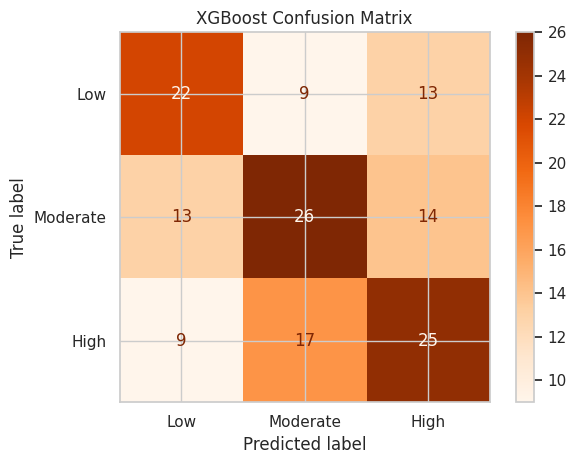

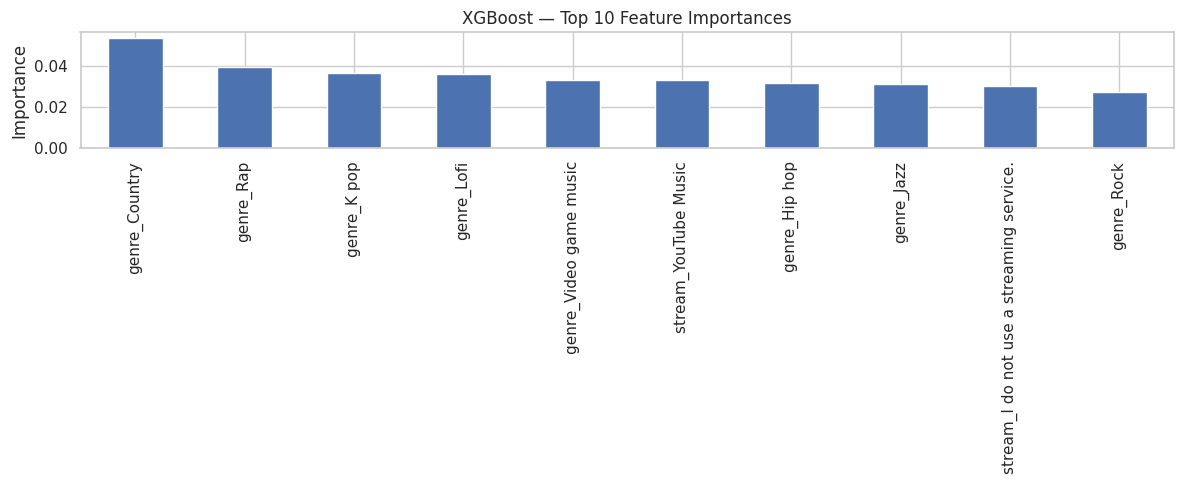

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Hyperparameter grid
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    XGBClassifier(
        objective="multi:softmax",
        num_class=3,
        random_state=42,
        eval_metric="mlogloss",
        verbosity=0
    ),
    param_grid=xgb_param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)
xgb_grid.fit(X_train_smote, y_train_smote)

print(f"Best params: {xgb_grid.best_params_}")
print(f"Best CV macro F1: {xgb_grid.best_score_:.3f}")

# Evaluate best model
xgb_model = xgb_grid.best_estimator_
y_pred_xgb = xgb_model.predict(X_test)
print(classification_report(y_test, y_pred_xgb, target_names=label_names))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_xgb,
    display_labels=label_names,
    cmap="Oranges"
)
plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

# Feature importance
feat_imp_xgb = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
feat_imp_xgb.sort_values(ascending=False).head(10).plot(kind="bar", figsize=(12, 5))
plt.title("XGBoost — Top 10 Feature Importances")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()